# Predicting the Severity of Road Traffic Accidents: Baseline Models
**ARTI 205 Machine Learning | Group 3**

A first, **untuned** comparison on `../Data/UK_collisions_final.csv` to choose the model we propose.
All models use the same split, the same encoding and the same class weights, so the comparison is fair.
Tuning (grid search + 5-fold cross-validation), balancing methods (SMOTE-NC, under-sampling) and SHAP come next.

In [1]:
import pandas as pd, numpy as np, time
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

df = pd.read_csv("../Data/UK_collisions_final.csv")
NUM = ["hour", "month", "speed_limit", "number_of_vehicles", "speed_x_vehicles", "speed_per_vehicle"]
CAT = [c for c in df.columns if c not in NUM + ["severity"]]
CLASSES = ["Slight", "Serious", "Fatal"]
y = df["severity"].map({c: i for i, c in enumerate(CLASSES)})
X = df.drop(columns="severity")
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"train {len(X_tr):,} | test {len(X_te):,} | fatal in test: {(y_te == 2).sum()}")
prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", StandardScaler(), NUM)])
w = compute_sample_weight("balanced", y_tr)   # cost-sensitive learning: rare classes weigh more

train 80,741 | test 20,186 | fatal in test: 300


In [2]:
models = {
    "Majority class (always 'Slight')": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.08, max_depth=6, subsample=0.9,
                             colsample_bytree=0.8, tree_method="hist", random_state=42, n_jobs=-1),
}
rows, preds = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    t = time.time()
    if isinstance(m, DummyClassifier): pipe.fit(X_tr, y_tr)          # the 'no model' reference, no weights
    else: pipe.fit(X_tr, y_tr, model__sample_weight=w)
    secs = time.time() - t
    p = pipe.predict(X_te); preds[name] = p
    r = recall_score(y_te, p, average=None, labels=[0, 1, 2], zero_division=0)
    rows.append({"model": name, "accuracy": accuracy_score(y_te, p), "macro F1": f1_score(y_te, p, average="macro"),
                 "recall Fatal": r[2], "recall Serious": r[1], "recall Slight": r[0], "train s": round(secs, 1)})
res = pd.DataFrame(rows).set_index("model").round(3)
res

,accuracy,macro F1,recall Fatal,recall Serious,recall Slight,train s
model,,,,,,
Majority class (always 'Slight'),0.752,0.286,0.000,0.000,1.000,0.3
Logistic Regression,0.528,0.371,0.663,0.377,0.572,5.6
Decision Tree,0.470,0.344,0.523,0.469,0.470,3.7
Random Forest,0.669,0.435,0.187,0.436,0.751,18.8
XGBoost,0.580,0.400,0.443,0.468,0.618,3.8


> Accuracy rewards the useless *always Slight* model (75%), while its fatal recall is **0**. We therefore compare models by **macro F1** and **fatal recall**.

best by macro F1: Random Forest
              precision    recall  f1-score   support

      Slight      0.818     0.751     0.783     15172
     Serious      0.363     0.436     0.396      4714
       Fatal      0.094     0.187     0.125       300

    accuracy                          0.669     20186
   macro avg      0.425     0.458     0.435     20186
weighted avg      0.701     0.669     0.683     20186



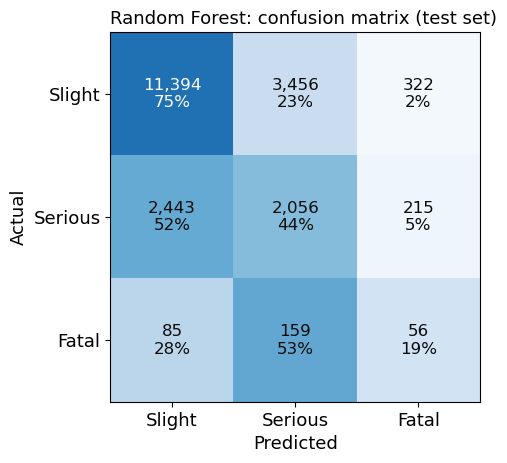

In [3]:
best = res.drop(index="Majority class (always 'Slight')")["macro F1"].idxmax()
print("best by macro F1:", best)
print(classification_report(y_te, preds[best], target_names=CLASSES, digits=3))
cm = confusion_matrix(y_te, preds[best], labels=[0, 1, 2])
fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({"font.family": "Inter" if "Inter" in fonts else "DejaVu Sans", "font.size": 13})
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        v = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]:,}\n{v:.0%}", ha="center", va="center", fontsize=12, color="white" if v > 0.55 else "#0b0b0b")
ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{best}: confusion matrix (test set)", loc="left", fontsize=13)
fig.savefig("figures/08_confusion_matrix.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()